In [1]:
import warnings
warnings.filterwarnings('ignore')

import xarray as xr
from glob import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cmocean.cm as cmo
import gsw
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from scipy.signal import savgol_filter
import matplotlib.patches as patches

from load_profiles import compute_mld, compute_mld_density
from utils import get_shelf_edge, nearest, prepare_eddies2plot, subplots_structure, make_map

In [2]:
import matplotlib as mpl

mpl.rcParams['xtick.labelsize'] = 12
mpl.rcParams['ytick.labelsize'] = 12

In [3]:
extent =[-47.5, -37.5, -28, -20.62] # max lat fits the gebco data I have for sheld egde contour

# set relative path to the source file
datadir = './../data/glider'
savedir = './../figures'

box = [-47.5, -37.5, -28, -20] 
timerange = [pd.to_datetime('2022-03-01'), 
             pd.to_datetime('2022-04-01')]

In [4]:
# loading eddies
ds_locs = xr.open_dataset(f"{datadir}/../sanagu2022/eddies_sanagu2022_daily.nc")

ds = xr.open_dataset(f"{datadir}/sg576_Azul_19")

# add density
ds['dens'] = gsw.sigma0(ds['salinity'], ds['temperature'])

# get shelf edge
edge = get_shelf_edge()

In [5]:
ds = ds.sel(time=slice(timerange[0], timerange[1]))
ds

<xarray.Dataset>
Dimensions:           (update: 1, time_raw: 540700, variables: 6, time: 132,
                       depth: 46)
Coordinates:
  * update            (update) int32 0
  * time              (time) datetime64[ns] 2022-03-01T05:25:18.500000 ... 20...
  * time_raw          (time_raw) datetime64[ns] 2021-11-22T11:32:30 ... 2022-...
  * depth             (depth) float32 5.0 10.0 15.0 20.0 ... 900.0 950.0 1e+03
Dimensions without coordinates: variables
Data variables: (12/27)
    qc                (time_raw, variables) int32 ...
    dive_start        (time) int32 ...
    dive_end          (time) int32 ...
    start_date        (time) datetime64[ns] ...
    end_date          (time) datetime64[ns] ...
    down_up           (time_raw) int32 ...
    ...                ...
    chlorophyll_raw   (time_raw) float32 ...
    cdom              (time, depth) float32 ...
    cdom_raw          (time_raw) float32 ...
    DAC               (time) float32 ...
    DAC_DIR           (time) float32 ...
    dens              (time, depth) float64 23.89 23.88 23.87 ... 27.26 nan
Attributes:
    title:            Glider Data
    glider_id:        576
    julian_day_unit:  seconds since 1970-01-01 00:00:00 UTC
    _FillValue:       -9999.9999

In [6]:
ds['pressure'] = gsw.p_from_z((-1)*ds['depth'], ds['latitude'])
ds['SA'] = gsw.SA_from_SP(ds['salinity'], ds['pressure'], ds['longitude'], ds['latitude'])
ds['CT'] = gsw.CT_from_t(ds['SA'], ds['temperature'], ds['pressure'])
ds['dens'] = gsw.sigma0(ds['SA'], ds['CT'])

# fixing attributes
ds['SA'].attrs['long_name'] = 'absolute salinity'
ds['SA'].attrs['standard_name'] = 'salt'
ds['SA'].attrs['units'] = 'g/kg'

ds['CT'].attrs['long_name'] = 'temperature'
ds['CT'].attrs['standard_name'] = 'temp'
ds['CT'].attrs['units'] = 'oC'

In [7]:
mld_list = []
for cast in range(ds.dims['time']):
    prof = ds.isel(time=cast)
    
    mld = compute_mld(prof['depth'], prof['SA'], prof['CT'], prof['dens'])
    
    mld_list.append(mld)
    
ds['mld'] = (('time'), mld_list)
ds['mld_smoothed'] = (('time'), savgol_filter(ds['mld'], 15, 2))

In [8]:
# defining chunks to help in the discussion of the Smax advection
chunks = {
    '[a]': ['2022-03-03', '2022-03-10', 'lime'],
    '[b]': ['2022-03-12', '2022-03-19', 'k'],
    '[c]': ['2022-03-21', '2022-03-26', 'white']
}

In [9]:
for k,item in chunks.items():
    ds_chunk = ds.sel(time=slice(item[0], item[1]))

    distance = gsw.distance([ds_chunk.longitude.values[0],ds_chunk.longitude.values[-1]],
                            [ds_chunk.latitude.values[0],ds_chunk.latitude.values[-1]])

    distance = distance/1e3
    print(f"{k}: {distance[0]:0.2f} km")

[a]: 78.83 km
[b]: 27.46 km
[c]: 77.36 km


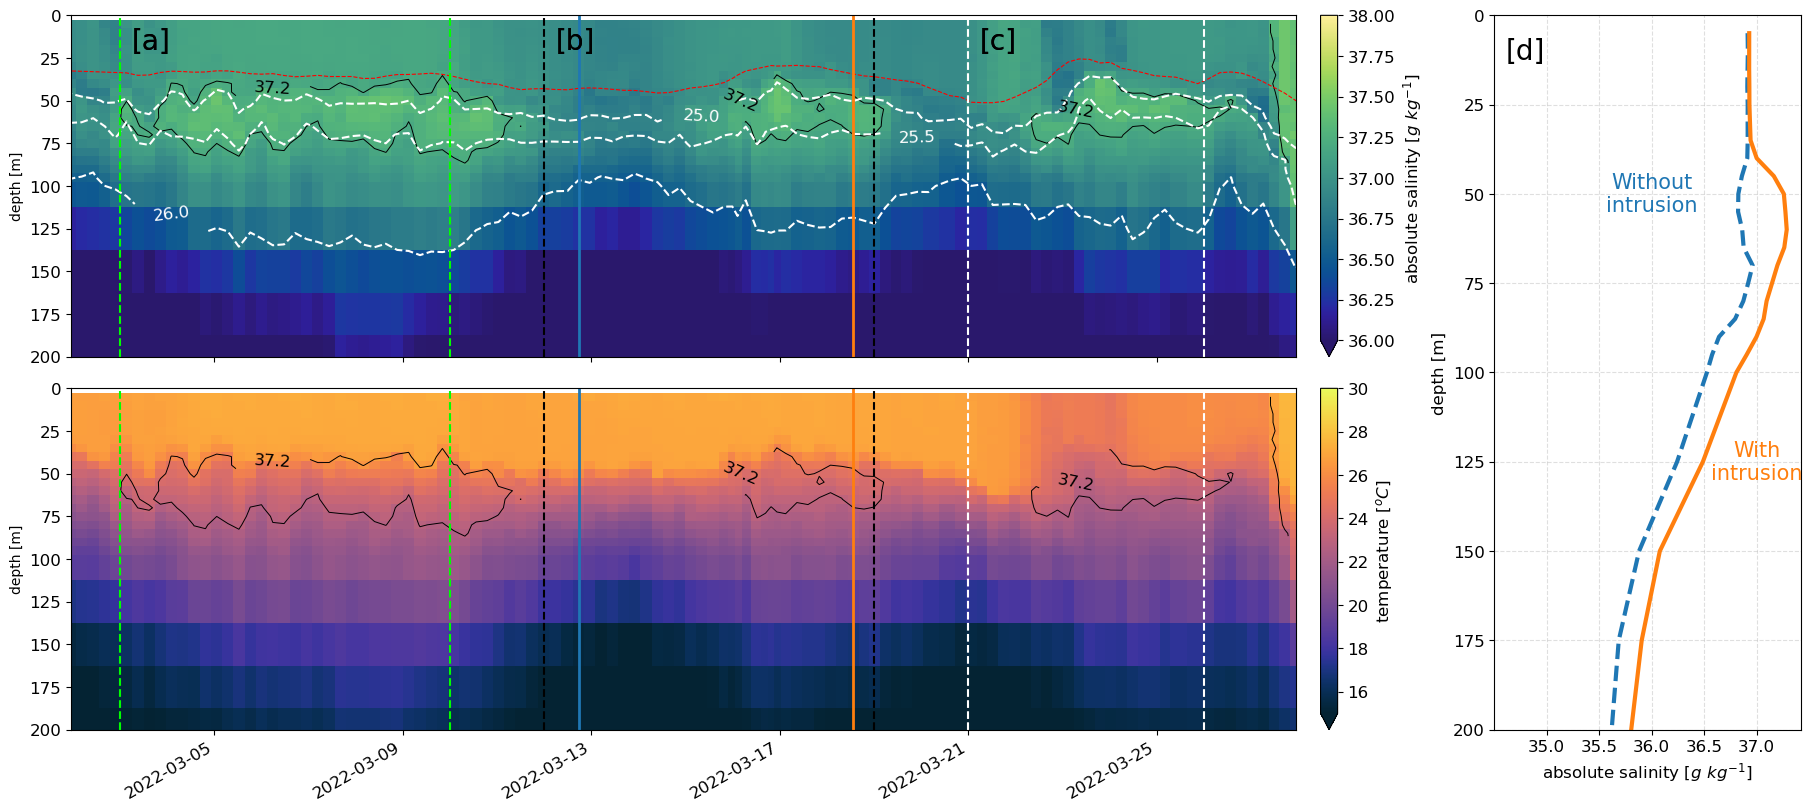

In [11]:
fig = plt.figure(layout="constrained", figsize=(18, 8))
axd = fig.subplot_mosaic(
    """
    AAAAC
    BBBBC
    """
)

axes_main = [axd[key] for key in ['A', 'B', 'C']]

##################################################################################################
axes = axes_main[:2]

## # __ SALINITY __ # ##
ax = axes[0]
pc = ds['SA'].plot.pcolormesh(ax=ax, x='time', y='depth', cmap=cmo.haline, vmin=36, vmax=38, cbar_kwargs={'pad': 0.02})
pc.colorbar.set_label(r'absolute salinity [$g\ kg^{-1}$]', fontsize=12)
cr1 = ds['SA'].plot.contour(ax=ax, levels=[37.2], colors='k', linewidths=[0.7], x='time', y='depth')
cr2 = ds['dens'].plot.contour(ax=ax, x='time', y='depth', levels=[25, 25.5, 26], colors='w', linestyles=['dashed'], lw=[0.2])

ax.clabel(cr1, fmt='%2.1f', colors='k', fontsize=12)
ax.clabel(cr2, fmt='%2.1f', colors='w', fontsize=12)

## # __ TEMPERATURE __ # ##
ax = axes[1]
pc = ds['CT'].plot.pcolormesh(ax=ax, x='time', y='depth', cmap=cmo.thermal, vmin=15, vmax=30, cbar_kwargs={'pad': 0.02})
pc.colorbar.set_label(r'temperature [$^oC$]', fontsize=12)

cr1 = ds['SA'].plot.contour(ax=ax, levels=[37.2], colors='k', linewidths=[0.7], x='time', y='depth')

ax.clabel(cr1, fmt='%2.1f', colors='k', fontsize=12)
# axes[1].clabel(cr2, fmt='%2.1f', colors='w', fontsize=10)

_ = [ax.set_ylim([0,200]) for ax in axes]
_ = [ax.invert_yaxis() for ax in axes]

_ = [ax.set_xlabel('') for ax in axes]

# adding smoothed MLD
ds['mld_smoothed'].plot(ax=axes[0], ls='--', c='r', lw=.8)

# adding chunks
for letter,chunk in chunks.items():
    period = [pd.to_datetime(chunk[0]), pd.to_datetime(chunk[1])]
    color = chunk[2]
    
    _ = [ax.axvline(period[0], c=color, lw=1.5, ls='dashed') for ax in axes]
    _ = [ax.axvline(period[1], c=color, lw=1.5, ls='dashed') for ax in axes]
    _ = [axes[0].text(pd.to_datetime(chunk[0]) + pd.Timedelta(hours=6), 20, 
                 letter, fontsize=20) for ax in axes]

_ = [ax.set_xlim([pd.to_datetime('2022-03-02') - pd.Timedelta(hours=1), 
                  pd.to_datetime('2022-03-28') - pd.Timedelta(hours=1)]) for ax in axes]

axes[0].set_xlabel('')
axes[0].set_xticklabels('')

axes[0].set_ylabel('depth [m]')
axes[1].set_ylabel('depth [m]')

### adding vertical profiles extracted for the comparison of the advective theory
firstProfile = pd.to_datetime('2022-03-12 17:33')
secndProfile = pd.to_datetime('2022-03-18 13:24')
_ = [ax.axvline(firstProfile, c='tab:blue', lw=2, ymin=-20) for ax in axes]
_ = [ax.axvline(secndProfile, c='tab:orange', lw=2, ) for ax in axes]
##################################################################################################


ax = axes_main[2]
styles = ['--', '-']

for i,t in enumerate(['2022-03-12 17:33','2022-03-18 13:24']):
    ds.sel(time=t)['SA'].plot(ax=ax, y='depth', ls=styles[i], lw=3.)

ax.grid(True, ls='--', alpha=.4)
ax.set_title('')
ax.set_ylabel('depth [m]', fontsize=12)
ax.set_xlabel(r'absolute salinity [$g\ kg^{-1}$]', fontsize=12)
ax.invert_yaxis()
ax.set_ylim([200,0])
_ = plt.xticks(fontsize=12)
_ = plt.yticks(fontsize=12)

ax.text(36.0, 50, 'Without\nintrusion', fontsize=15, color='tab:blue', ha='center', va='center')
ax.text(37.0, 125, 'With\nintrusion', fontsize=15, color='tab:orange', ha='center', va='center')

ax.text(34.8, 10, '[d]', fontsize=20, color='k', ha='center', va='center')

style = "Simple, tail_width=0.5, head_width=4, head_length=8"
kw = dict(arrowstyle=style, color="tab:blue")
a1 = patches.FancyArrowPatch((36, 58), (36.8, 70), 
                             connectionstyle="arc3,rad=.2", **kw)

style = "Simple, tail_width=0.5, head_width=4, head_length=8"
kw = dict(arrowstyle=style, color="tab:orange")
a2 = patches.FancyArrowPatch((37, 120), (37.3, 62), 
                             connectionstyle="arc3,rad=.2", **kw)
for a in [a1, a2]:
    plt.gca().add_patch(a)
    
    
fig.patch.set_alpha(1.0)
# plt.subplots_adjust(hspace=.05)
plt.savefig('../figures/manuscript/00_manuscript_glider_transect.png', bbox_inches="tight", dpi=300)

## new version

In [12]:
# defining chunks to help in the discussion of the Smax advection
chunks = {
    'offshore': ['2022-03-03', '2022-03-10', 'lime'],
    'loop': ['2022-03-12', '2022-03-19', 'k'],
    'shelf': ['2022-03-21', '2022-03-26', 'white']
}

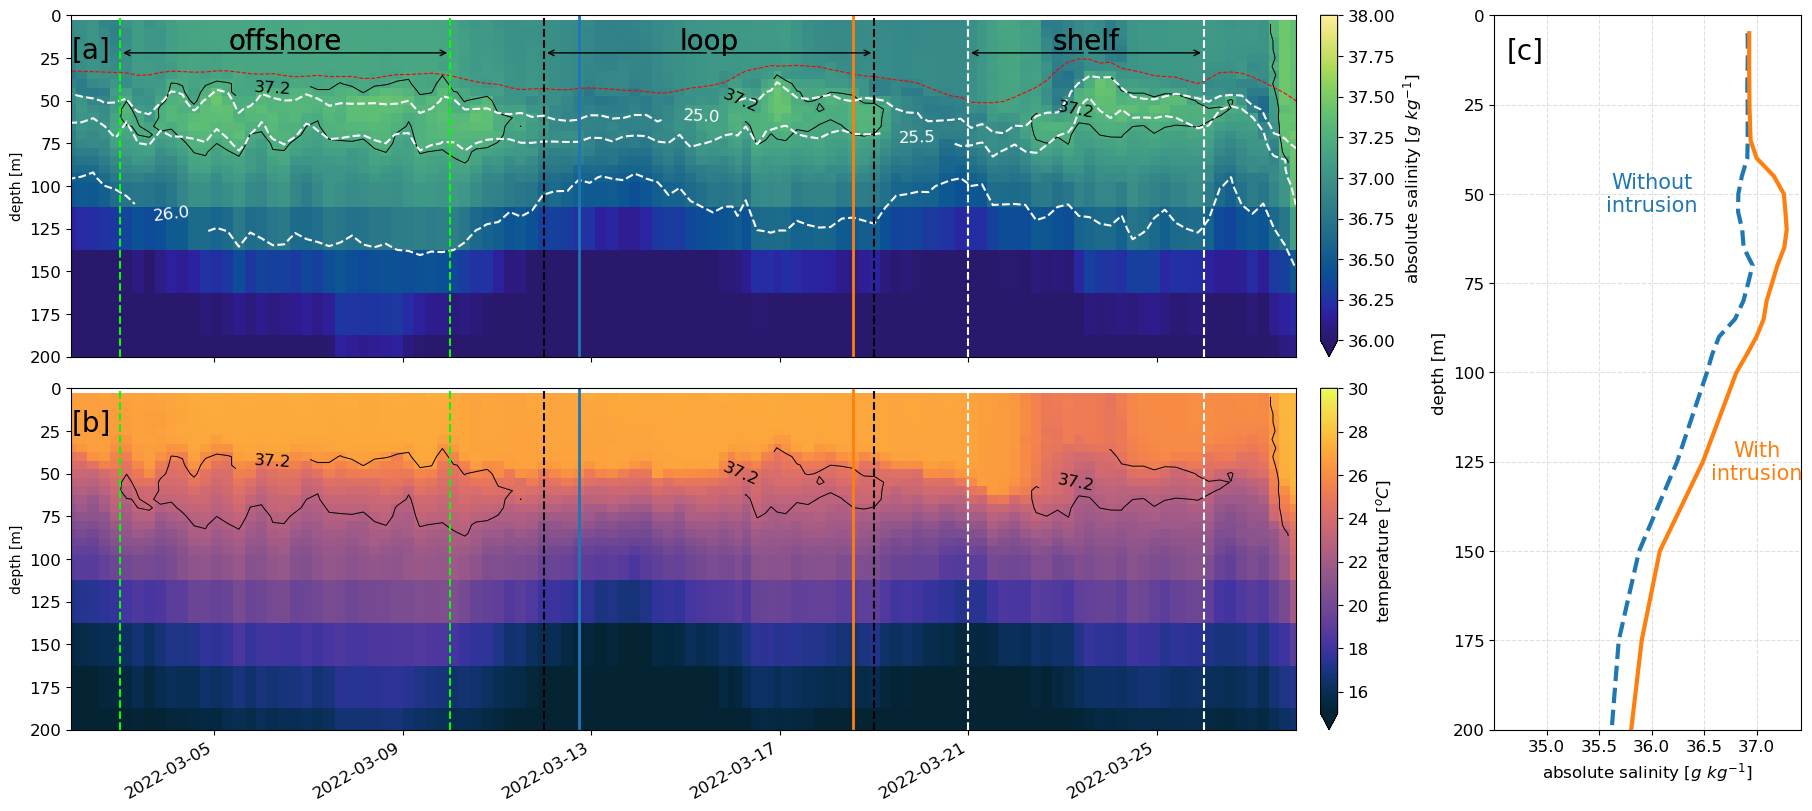

In [13]:
fig = plt.figure(layout="constrained", figsize=(18, 8))
axd = fig.subplot_mosaic(
    """
    AAAAC
    BBBBC
    """
)

axes_main = [axd[key] for key in ['A', 'B', 'C']]

##################################################################################################
axes = axes_main[:2]

## # __ SALINITY __ # ##
ax = axes[0]

ax.set_title("[a]", loc='left', fontsize=20, y=0.85)

pc = ds['SA'].plot.pcolormesh(ax=ax, x='time', y='depth', cmap=cmo.haline, vmin=36, vmax=38, cbar_kwargs={'pad': 0.02})
pc.colorbar.set_label(r'absolute salinity [$g\ kg^{-1}$]', fontsize=12)
cr1 = ds['SA'].plot.contour(ax=ax, levels=[37.2], colors='k', linewidths=[0.7], x='time', y='depth')
cr2 = ds['dens'].plot.contour(ax=ax, x='time', y='depth', levels=[25, 25.5, 26], colors='w', linestyles=['dashed'], lw=[0.2])

ax.clabel(cr1, fmt='%2.1f', colors='k', fontsize=12)
ax.clabel(cr2, fmt='%2.1f', colors='w', fontsize=12)

## # __ TEMPERATURE __ # ##
ax = axes[1]
ax.set_title("[b]", loc='left', fontsize=20, y=0.85)

pc = ds['CT'].plot.pcolormesh(ax=ax, x='time', y='depth', cmap=cmo.thermal, vmin=15, vmax=30, cbar_kwargs={'pad': 0.02})
pc.colorbar.set_label(r'temperature [$^oC$]', fontsize=12)

cr1 = ds['SA'].plot.contour(ax=ax, levels=[37.2], colors='k', linewidths=[0.7], x='time', y='depth')

ax.clabel(cr1, fmt='%2.1f', colors='k', fontsize=12)
# axes[1].clabel(cr2, fmt='%2.1f', colors='w', fontsize=10)

_ = [ax.set_ylim([0,200]) for ax in axes]
_ = [ax.invert_yaxis() for ax in axes]

_ = [ax.set_xlabel('') for ax in axes]

# adding smoothed MLD
ds['mld_smoothed'].plot(ax=axes[0], ls='--', c='r', lw=.8)

# adding chunks
for letter,chunk in chunks.items():
    period = [pd.to_datetime(chunk[0]), pd.to_datetime(chunk[1])]
    color = chunk[2]
    central_dt = period[0] + (period[1] - period[0]) / 2
    
    _ = [ax.axvline(period[0], c=color, lw=1.5, ls='dashed') for ax in axes]
    _ = [ax.axvline(period[1], c=color, lw=1.5, ls='dashed') for ax in axes]
    _ = [axes[0].text(central_dt, 20, 
                 letter, fontsize=20, ha='center') for ax in axes]
    
    # Setas (usando annotate)
    arrowprops = dict(arrowstyle="->", color='k')
    for ax in axes[:1]:
        # Do texto ao início
        ax.annotate('', xy=(period[0], 22), xytext=(central_dt, 22), arrowprops=arrowprops)
        
        # Do texto ao fim
        ax.annotate('', xy=(period[1], 22), xytext=(central_dt, 22), arrowprops=arrowprops)


_ = [ax.set_xlim([pd.to_datetime('2022-03-02') - pd.Timedelta(hours=1), 
                  pd.to_datetime('2022-03-28') - pd.Timedelta(hours=1)]) for ax in axes]

axes[0].set_xlabel('')
axes[0].set_xticklabels('')

axes[0].set_ylabel('depth [m]')
axes[1].set_ylabel('depth [m]')

### adding vertical profiles extracted for the comparison of the advective theory
firstProfile = pd.to_datetime('2022-03-12 17:33')
secndProfile = pd.to_datetime('2022-03-18 13:24')
_ = [ax.axvline(firstProfile, c='tab:blue', lw=2, ymin=-20) for ax in axes]
_ = [ax.axvline(secndProfile, c='tab:orange', lw=2, ) for ax in axes]
##################################################################################################


ax = axes_main[2]
styles = ['--', '-']

for i,t in enumerate(['2022-03-12 17:33','2022-03-18 13:24']):
    ds.sel(time=t)['SA'].plot(ax=ax, y='depth', ls=styles[i], lw=3.)

ax.grid(True, ls='--', alpha=.4)
ax.set_title('')
ax.set_ylabel('depth [m]', fontsize=12)
ax.set_xlabel(r'absolute salinity [$g\ kg^{-1}$]', fontsize=12)
ax.invert_yaxis()
ax.set_ylim([200,0])
_ = plt.xticks(fontsize=12)
_ = plt.yticks(fontsize=12)

ax.text(36.0, 50, 'Without\nintrusion', fontsize=15, color='tab:blue', ha='center', va='center')
ax.text(37.0, 125, 'With\nintrusion', fontsize=15, color='tab:orange', ha='center', va='center')

ax.text(34.8, 10, '[c]', fontsize=20, color='k', ha='center', va='center')

style = "Simple, tail_width=0.5, head_width=4, head_length=8"
kw = dict(arrowstyle=style, color="tab:blue")
a1 = patches.FancyArrowPatch((36, 58), (36.8, 70), 
                             connectionstyle="arc3,rad=.2", **kw)

style = "Simple, tail_width=0.5, head_width=4, head_length=8"
kw = dict(arrowstyle=style, color="tab:orange")
a2 = patches.FancyArrowPatch((37, 120), (37.3, 62), 
                             connectionstyle="arc3,rad=.2", **kw)
for a in [a1, a2]:
    plt.gca().add_patch(a)    
    
fig.patch.set_alpha(1.0)
# plt.subplots_adjust(hspace=.05)
plt.savefig('../figures/manuscript/00_manuscript_glider_transect.png', bbox_inches="tight", dpi=300)

In [46]:
axes

[<Axes: label='A', title={'left': '[a]'}>,
 <Axes: label='B', title={'left': '[b]'}>]

## ptbr

In [ ]:
fig = plt.figure(layout="constrained", figsize=(18, 8))
axd = fig.subplot_mosaic(
    """
    AAAAC
    BBBBC
    """
)

axes_main = [axd[key] for key in ['A', 'B', 'C']]

##################################################################################################
axes = axes_main[:2]

## # __ SALINITY __ # ##
ax = axes[0]
pc = ds['SA'].plot.pcolormesh(ax=ax, x='time', y='depth', cmap=cmo.haline, vmin=36, vmax=38, cbar_kwargs={'pad': 0.02})
pc.colorbar.set_label(r'salinidade absoluta [$g\ kg^{-1}$]', fontsize=12)
cr1 = ds['SA'].plot.contour(ax=ax, levels=[37.2], colors='k', linewidths=[0.7], x='time', y='depth')
cr2 = ds['dens'].plot.contour(ax=ax, x='time', y='depth', levels=[25, 25.5, 26], colors='w', linestyles=['dashed'], lw=[0.2])

ax.clabel(cr1, fmt='%2.1f', colors='k', fontsize=10)
ax.clabel(cr2, fmt='%2.1f', colors='w', fontsize=10)

## # __ TEMPERATURE __ # ##
ax = axes[1]
pc = ds['CT'].plot.pcolormesh(ax=ax, x='time', y='depth', cmap=cmo.thermal, vmin=15, vmax=30, cbar_kwargs={'pad': 0.02})
pc.colorbar.set_label(r'temperatura [$^oC$]', fontsize=12)
cr1 = ds['SA'].plot.contour(ax=ax, levels=[37.2], colors='k', linewidths=[0.7], x='time', y='depth')

ax.clabel(cr1, fmt='%2.1f', colors='k', fontsize=12)
# axes[1].clabel(cr2, fmt='%2.1f', colors='w', fontsize=10)

_ = [ax.set_ylim([0,200]) for ax in axes]
_ = [ax.invert_yaxis() for ax in axes]

_ = [ax.set_xlabel('') for ax in axes]

# adding smoothed MLD
ds['mld_smoothed'].plot(ax=axes[0], ls='--', c='r', lw=.8)

# adding chunks
for letter,chunk in chunks.items():
    period = [pd.to_datetime(chunk[0]), pd.to_datetime(chunk[1])]
    color = chunk[2]
    
    _ = [ax.axvline(period[0], c=color, lw=1.5, ls='dashed') for ax in axes]
    _ = [ax.axvline(period[1], c=color, lw=1.5, ls='dashed') for ax in axes]
    _ = [axes[0].text(pd.to_datetime(chunk[0]) + pd.Timedelta(hours=6), 20, 
                 letter, fontsize=20) for ax in axes]

_ = [ax.set_xlim([pd.to_datetime('2022-03-02') - pd.Timedelta(hours=1), 
                  pd.to_datetime('2022-03-28') - pd.Timedelta(hours=1)]) for ax in axes]

axes[0].set_xlabel('')
axes[0].set_xticklabels('')

axes[0].set_ylabel('')
axes[1].set_ylabel('')

### adding vertical profiles extracted for the comparison of the advective theory
firstProfile = pd.to_datetime('2022-03-12 17:33')
secndProfile = pd.to_datetime('2022-03-18 13:24')
_ = [ax.axvline(firstProfile, c='tab:blue', lw=2, ymin=-20) for ax in axes]
_ = [ax.axvline(secndProfile, c='tab:orange', lw=2, ) for ax in axes]
##################################################################################################


ax = axes_main[2]
styles = ['--', '-']

for i,t in enumerate(['2022-03-12 17:33','2022-03-18 13:24']):
    ds.sel(time=t)['SA'].plot(ax=ax, y='depth', ls=styles[i], lw=3.)

ax.grid(True, ls='--', alpha=.4)
ax.set_title('')
ax.set_ylabel('profundidade [m]', fontsize=12)
ax.set_xlabel(r'salinidade absoluta [$g\ kg^{-1}$]', fontsize=12)
ax.invert_yaxis()
ax.set_ylim([200,0])
_ = plt.xticks(fontsize=12)
_ = plt.yticks(fontsize=12)

ax.text(36.0, 50, 'Sem\nintrusão', fontsize=15, color='tab:blue', ha='center', va='center')
ax.text(37.0, 125, 'Com\nintrusão', fontsize=15, color='tab:orange', ha='center', va='center')

ax.text(34.8, 10, '[d]', fontsize=20, color='k', ha='center', va='center')

style = "Simple, tail_width=0.5, head_width=4, head_length=8"
kw = dict(arrowstyle=style, color="tab:blue")
a1 = patches.FancyArrowPatch((36, 58), (36.8, 70), 
                             connectionstyle="arc3,rad=.2", **kw)

style = "Simple, tail_width=0.5, head_width=4, head_length=8"
kw = dict(arrowstyle=style, color="tab:orange")
a2 = patches.FancyArrowPatch((37, 120), (37.3, 62), 
                             connectionstyle="arc3,rad=.2", **kw)
for a in [a1, a2]:
    plt.gca().add_patch(a)
    
    
fig.patch.set_alpha(1.0)
# plt.subplots_adjust(hspace=.05)
plt.savefig('../figures/manuscript/00_manuscript_glider_transect_ptbr.png', bbox_inches="tight")

In [19]:
## initial profile for PWP running
ic = ds.sel(time='2022-03-12 17:33')[['SA', 'CT', 'dens', 'latitude']]
ic['lat'] = ic['latitude'].mean()
ic.to_netcdf('../data/pwp_ic_file.nc')

In [11]:
ds.sel(time='2022-03-12 17:33')['latitude'].mean().item()

-24.679283142089844

In [12]:
ds.sel(time='2022-03-12 17:33')['longitude'].mean().item()

-42.75074005126953

In [8]:
## initial profile for PWP running
rp = ds.sel(time='2022-03-18 13:24')[['SA', 'CT', 'dens', 'latitude']]
rp.to_netcdf('../data/pwp_realprofile_file.nc')

In [ ]:
ds_list = []
for i,t in enumerate(['2022-03-12 17:33','2022-03-18 13:24']):
    _ds = ds.sel(time=t)[['SA', 'CT', 'dens', 'latitude']].to_dataframe()
    ds_list.append(_ds)

In [12]:
ds.sel(time=t)

<xarray.Dataset>
Dimensions:           (update: 1, time_raw: 540700, variables: 6, time: 1,
                       depth: 46)
Coordinates:
  * update            (update) int32 0
  * time              (time) datetime64[ns] 2022-03-12T17:33:07
  * time_raw          (time_raw) datetime64[ns] 2021-11-22T11:32:30 ... 2022-...
  * depth             (depth) float32 5.0 10.0 15.0 20.0 ... 900.0 950.0 1e+03
Dimensions without coordinates: variables
Data variables: (12/32)
    qc                (time_raw, variables) int32 0 0 1 0 0 1 0 ... 0 0 1 1 1 1
    dive_start        (time) int32 ...
    dive_end          (time) int32 ...
    start_date        (time) datetime64[ns] ...
    end_date          (time) datetime64[ns] ...
    down_up           (time_raw) int32 0 0 0 0 0 0 0 0 0 0 ... 1 1 1 1 1 1 1 1 1
    ...                ...
    dens              (time, depth) float64 24.0 24.03 24.04 ... 27.41 27.46 nan
    pressure          (depth, time) float64 5.032 10.06 15.1 ... 958.3 1.009e+03
    SA                (time, depth) float64 36.91 36.92 36.91 ... 34.69 nan
    CT                (time, depth) float64 27.04 26.93 26.91 ... 3.516 nan
    mld               (time) float64 45.0
    mld_smoothed      (time) float64 42.77
Attributes:
    title:            Glider Data
    glider_id:        576
    julian_day_unit:  seconds since 1970-01-01 00:00:00 UTC
    _FillValue:       -9999.9999

In [10]:
ds_list[0]

SA
time                depth            
2022-03-12 17:33:07 5.0     36.914348
                    10.0    36.916621
                    15.0    36.914007
                    20.0    36.911592
                    25.0    36.915184
                    30.0    36.914683
                    35.0    36.915118
                    40.0    36.911234
                    45.0    36.859866
                    50.0    36.826078
                    55.0    36.823589
                    60.0    36.862758
                    65.0    36.876593
                    70.0    36.961911
                    75.0    36.919221
                    80.0    36.873509
                    85.0    36.795403
                    90.0    36.642295
                    95.0    36.576343
                    100.0   36.526840
                    125.0   36.242808
                    150.0   35.881137
                    175.0   35.687666
                    200.0   35.620245
                    225.0   35.554255
                    250.0   35.494930
                    275.0   35.461179
                    300.0   35.394391
                    325.0   35.334503
                    350.0   35.289356
                    375.0   35.238361
                    400.0   35.169146
                    425.0   35.112578
                    450.0   35.053834
                    475.0   35.002119
                    500.0   34.957886
                    550.0   34.853185
                    600.0   34.754944
                    650.0   34.689686
                    700.0   34.651546
                    750.0   34.651807
                    800.0   34.638509
                    850.0   34.636676
                    900.0   34.655556
                    950.0   34.685952
                    1000.0        NaN